In [1]:
import os, copy, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.utils import make_grid
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
MODEL_NAME = "mlp_classifier"
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
FIG_DIR = "figures"
RESULTS_DIR = "results"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

BATCH_SIZE = 128
ORIGINAL_DIM = 28 * 28
HIDDEN_DIM = 256
LATENT_DIM = 64
CLF_EPOCHS = 20
DEC_EPOCHS = 30
LEARN_RATE = 1e-3

In [3]:
train_raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])
full = TensorDataset(images, labels)

n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(
    full, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
test_targets = labels[torch.tensor(test_set.indices)]
VIS_IDX = [int(torch.nonzero(test_targets == c)[0]) for c in range(10)]
x_vis = torch.stack([test_set[i][0] for i in VIS_IDX])
x_a, x_b = x_vis[1:2], x_vis[9:10]
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

train=56000  val=7000  test=7000


In [4]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def reconstruction_metrics(reconstruct, loader):
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)
    ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    se, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = reconstruct(x).clamp(0, 1)
        se += F.mse_loss(x_hat, x, reduction="sum").item()
        count += x.numel()
        psnr.update(x_hat, x)
        ssim.update(x_hat, x)
    return {"test_mse": se / count, "test_psnr": psnr.compute().item(), "test_ssim": ssim.compute().item()}


@torch.no_grad()
def compute_fid(generate, n_samples=len(test_set), batch=250):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, _ in test_loader:
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=True)
    done = 0
    while done < n_samples:
        b = min(batch, n_samples - done)
        fid.update(generate(b).clamp(0, 1).repeat(1, 3, 1, 1), real=False)
        done += b
    return fid.compute().item()


@torch.no_grad()
def measure_latency(fn, n_warmup=5, n_runs=20):
    for _ in range(n_warmup):
        fn()
    sync()
    start = time.perf_counter()
    for _ in range(n_runs):
        fn()
    sync()
    return (time.perf_counter() - start) / n_runs * 1000


def show_grid(images, nrow, title=None):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(grid.shape[2] / 40, grid.shape[1] / 40))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_history(history, keys):
    plt.figure(figsize=(6, 3.5))
    for k in keys:
        plt.plot(range(1, len(history[k]) + 1), history[k], label=k)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


def save_results(results, outputs):
    with open(os.path.join(RESULTS_DIR, f"{MODEL_NAME}.json"), "w") as f:
        json.dump(results, f, indent=2)
    torch.save(outputs, os.path.join(RESULTS_DIR, f"{MODEL_NAME}_outputs.pt"))


def print_results(results):
    print(json.dumps({k: v for k, v in results.items() if k != "loss_history"}, indent=2))


x_latency = next(iter(test_loader))[0][:64].to(device)

In [5]:
class MLPClassifier(nn.Module):
    def __init__(self, hidden_dim, latent_dim, num_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(ORIGINAL_DIM, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, latent_dim)
        self.fc3 = nn.Linear(latent_dim, num_classes)

    def features(self, x):
        h = F.relu(self.fc1(x.flatten(1)))
        return F.relu(self.fc2(h))

    def forward(self, x):
        return self.fc3(self.features(x))


def train(model, optimizer, x, y):
    loss = F.cross_entropy(model(x), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = sum((model(x.to(device)).argmax(1).cpu() == y).sum().item() for x, y in loader)
    return correct / len(loader.dataset)


def train_clf_loop(model, opt, loader, epochs):
    history = {"train_loss": [], "val_acc": []}
    epoch_times = []
    best_acc, best_state = 0.0, None
    for epoch in range(epochs):
        model.train()
        loss_list = []
        sync()
        start = time.perf_counter()
        for x, y in loader:
            loss_list.append(train(model, opt, x.to(device), y.to(device)))
        sync()
        epoch_times.append(time.perf_counter() - start)

        history["train_loss"].append(float(np.mean(loss_list)))
        history["val_acc"].append(accuracy(model, val_loader))
        if history["val_acc"][-1] > best_acc:
            best_acc, best_state = history["val_acc"][-1], copy.deepcopy(model.state_dict())
        print(f"Epoch[{epoch + 1} / {epochs}], Loss : {history['train_loss'][-1]:.4f}, "
              f"Val Acc : {history['val_acc'][-1]:.4f}, Time : {epoch_times[-1]:.1f}s")
    model.load_state_dict(best_state)
    return history, epoch_times

In [6]:
clf = MLPClassifier(HIDDEN_DIM, LATENT_DIM).to(device)
clf_optimizer = torch.optim.Adam(clf.parameters(), lr=LEARN_RATE)
print(clf)

history, epoch_times = train_clf_loop(clf, clf_optimizer, train_loader, CLF_EPOCHS)
test_acc = accuracy(clf, test_loader)
print(f"Test Accuracy : {test_acc:.4f}", "(>= 0.88)" if test_acc >= 0.88 else "(below 0.88)")
torch.save(clf.state_dict(), os.path.join(CKPT_DIR, "mlp_classifier.pt"))

W1, W2, W3 = (w.detach() for w in (clf.fc1.weight, clf.fc2.weight, clf.fc3.weight))
with torch.no_grad():
    z_test = torch.cat([clf.features(x.to(device)) for x, _ in test_loader])
print("W1", tuple(W1.shape), "W2", tuple(W2.shape), "W3", tuple(W3.shape), "z_MLP", tuple(z_test.shape))

MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


Epoch[1 / 20], Loss : 0.6009, Val Acc : 0.8419, Time : 1.0s


Epoch[2 / 20], Loss : 0.4061, Val Acc : 0.8603, Time : 0.8s


Epoch[3 / 20], Loss : 0.3639, Val Acc : 0.8679, Time : 0.8s


Epoch[4 / 20], Loss : 0.3335, Val Acc : 0.8730, Time : 0.8s


Epoch[5 / 20], Loss : 0.3145, Val Acc : 0.8706, Time : 0.8s


... (11 outputs left out)

Epoch[17 / 20], Loss : 0.1945, Val Acc : 0.8939, Time : 0.9s


Epoch[18 / 20], Loss : 0.1912, Val Acc : 0.8869, Time : 0.9s


Epoch[19 / 20], Loss : 0.1850, Val Acc : 0.8943, Time : 0.9s


Epoch[20 / 20], Loss : 0.1787, Val Acc : 0.8920, Time : 0.9s
Test Accuracy : 0.8877 (>= 0.88)
W1 (256, 784) W2 (64, 256) W3 (10, 64) z_MLP (7000, 64)


W1 (256, 784) | rank 256 | ||W^T W - I||_F / ||I||_F = 12.372
W2 (64, 256) | rank 64 | ||W^T W - I||_F / ||I||_F = 3.591
W3 (10, 64) | rank 10 | ||W^T W - I||_F / ||I||_F = 1.438
ReLU zeros: h1 0.700 | z_MLP 0.462


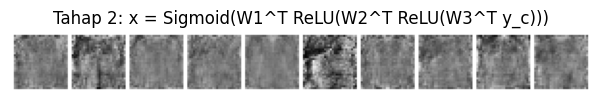

In [7]:
for name, W in [("W1", W1), ("W2", W2), ("W3", W3)]:
    gram = W.T @ W
    eye = torch.eye(gram.shape[0], device=device)
    rel = (torch.linalg.norm(gram - eye) / torch.linalg.norm(eye)).item()
    print(f"{name} {tuple(W.shape)} | rank {torch.linalg.matrix_rank(W).item()} | "
          f"||W^T W - I||_F / ||I||_F = {rel:.3f}")

with torch.no_grad():
    h1 = torch.cat([F.relu(clf.fc1(x.to(device).flatten(1))) for x, _ in test_loader])
print(f"ReLU zeros: h1 {(h1 == 0).float().mean().item():.3f} | z_MLP {(z_test == 0).float().mean().item():.3f}")

with torch.no_grad():
    y_onehot = torch.eye(10, device=device)
    z_hat = F.relu(y_onehot @ W3)
    h_hat = F.relu(z_hat @ W2)
    class_proj = torch.sigmoid(h_hat @ W1).view(-1, 1, 28, 28).cpu()
show_grid(class_proj, nrow=10, title="Tahap 2: x = Sigmoid(W1^T ReLU(W2^T ReLU(W3^T y_c)))")

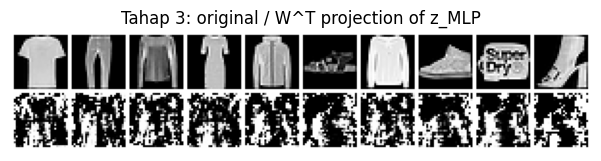

{'test_mse': 0.2823907438673014, 'test_psnr': 5.491495132446289, 'test_ssim': 0.05779876559972763}


In [8]:
transpose_project = lambda x: torch.sigmoid(F.relu(clf.features(x) @ W2) @ W1).view(-1, 1, 28, 28)
with torch.no_grad():
    latent_proj = transpose_project(x_vis.to(device)).cpu()
show_grid(torch.cat([x_vis, latent_proj]), nrow=10, title="Tahap 3: original / W^T projection of z_MLP")
transpose_metrics = reconstruction_metrics(transpose_project, test_loader)
print(transpose_metrics)

In [9]:
for p in clf.parameters():
    p.requires_grad = False
clf.eval()


class Decoder(nn.Module):
    def __init__(self, hidden_dim, latent_dim):
        super().__init__()
        self.hidden_layer = nn.Linear(latent_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, ORIGINAL_DIM)

    def forward(self, encoded):
        h = F.relu(self.hidden_layer(encoded))
        return torch.sigmoid(self.output_layer(h)).view(-1, 1, 28, 28)


def ae_loss(preds, real):
    return torch.mean((preds - real) ** 2)


def train_decoder(decoder, optimizer, original):
    with torch.no_grad():
        z = clf.features(original)
    recon_error = ae_loss(decoder(z), original)
    optimizer.zero_grad()
    recon_error.backward()
    optimizer.step()
    return recon_error.item()


@torch.no_grad()
def evaluate_decoder(decoder, loader):
    decoder.eval()
    return np.mean([ae_loss(decoder(clf.features(x.to(device))), x.to(device)).item() for x, _ in loader])


def train_decoder_loop(decoder, opt, loader, epochs):
    history = {"train_loss": [], "val_loss": []}
    best_val, best_state = float("inf"), None
    for epoch in range(epochs):
        decoder.train()
        loss_list = [train_decoder(decoder, opt, x.to(device)) for x, _ in loader]
        history["train_loss"].append(float(np.mean(loss_list)))
        history["val_loss"].append(float(evaluate_decoder(decoder, val_loader)))
        if history["val_loss"][-1] < best_val:
            best_val, best_state = history["val_loss"][-1], copy.deepcopy(decoder.state_dict())
        print(f"Epoch[{epoch + 1} / {epochs}], Loss : {history['train_loss'][-1]:.6f}, "
              f"Val Loss : {history['val_loss'][-1]:.6f}")
    decoder.load_state_dict(best_state)
    return history

Epoch[1 / 30], Loss : 0.034864, Val Loss : 0.025927


Epoch[2 / 30], Loss : 0.023556, Val Loss : 0.022406


Epoch[3 / 30], Loss : 0.021390, Val Loss : 0.021174


Epoch[4 / 30], Loss : 0.020278, Val Loss : 0.020285


Epoch[5 / 30], Loss : 0.019538, Val Loss : 0.019632


Epoch[6 / 30], Loss : 0.018994, Val Loss : 0.019121


... (20 outputs left out)

Epoch[27 / 30], Loss : 0.016030, Val Loss : 0.016626


Epoch[28 / 30], Loss : 0.015982, Val Loss : 0.016777


Epoch[29 / 30], Loss : 0.015935, Val Loss : 0.016715


Epoch[30 / 30], Loss : 0.015908, Val Loss : 0.016604
                               MSE      PSNR      SSIM
W^T projection             0.28239      5.49    0.0578
Frozen z_MLP decoder       0.01659     17.80    0.7213
Vanilla AE z_AE            0.00656     21.83    0.8641


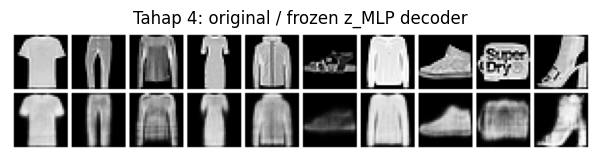

In [10]:
decoder = Decoder(HIDDEN_DIM, LATENT_DIM).to(device)
decoder_optimizer = torch.optim.Adam(decoder.parameters(), lr=LEARN_RATE)
dec_history = train_decoder_loop(decoder, decoder_optimizer, train_loader, DEC_EPOCHS)
decoder.eval()
torch.save(decoder.state_dict(), os.path.join(CKPT_DIR, "mlp_frozen_decoder.pt"))

frozen_metrics = reconstruction_metrics(lambda x: decoder(clf.features(x)), test_loader)
with open(os.path.join(RESULTS_DIR, "vanilla_ae.json")) as f:
    ae_results = json.load(f)
print(f"{'':24s}{'MSE':>10s}{'PSNR':>10s}{'SSIM':>10s}")
for name, m in [("W^T projection", transpose_metrics), ("Frozen z_MLP decoder", frozen_metrics),
                ("Vanilla AE z_AE", ae_results)]:
    print(f"{name:24s}{m['test_mse']:10.5f}{m['test_psnr']:10.2f}{m['test_ssim']:10.4f}")

with torch.no_grad():
    frozen_recon = decoder(clf.features(x_vis.to(device))).cpu()
show_grid(torch.cat([x_vis, frozen_recon]), nrow=10, title="Tahap 4: original / frozen z_MLP decoder")

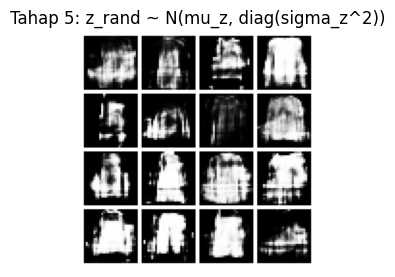

FID of MLP-latent samples: 148.22


In [11]:
mu_z, sigma_z = z_test.mean(0), z_test.std(0)
sample_mlp_latent = lambda n: decoder(mu_z + sigma_z * torch.randn(n, LATENT_DIM, device=device))

set_seed()
with torch.no_grad():
    prior_samples = sample_mlp_latent(16).cpu()
show_grid(prior_samples, nrow=4, title="Tahap 5: z_rand ~ N(mu_z, diag(sigma_z^2))")
prior_fid = compute_fid(sample_mlp_latent)
print(f"FID of MLP-latent samples: {prior_fid:.2f}")

In [12]:
results = {"model": MODEL_NAME, "latent_dim": LATENT_DIM, "test_accuracy": test_acc,
           "train_time_per_epoch_s": float(np.mean(epoch_times)),
           "transpose_projection": transpose_metrics, "frozen_decoder": frozen_metrics,
           "prior_sampling_fid": prior_fid,
           "loss_history": {"classifier": history, "frozen_decoder": dec_history}}
save_results(results, {"class_proj": class_proj, "latent_proj": latent_proj,
                       "frozen_recon": frozen_recon, "prior_samples": prior_samples})